# **Used Cars Price Prediction**

## **Problem Definition**

### **The Context:**

 - Why is this problem important to solve?

### **The objective:**

 - What is the intended goal?

### **The key questions:**

- What are the key questions that need to be answered?

### **The problem formulation**:

- What is it that we are trying to solve using data science?

### **Data Dictionary**

**S.No.** : Serial Number

**Name** : Name of the car which includes Brand name and Model name

**Location** : The location in which the car is being sold or is available for purchase (Cities)

**Year** : Manufacturing year of the car

**Kilometers_driven** : The total kilometers driven in the car by the previous owner(s) in KM

**Fuel_Type** : The type of fuel used by the car (Petrol, Diesel, Electric, CNG, LPG)

**Transmission** : The type of transmission used by the car (Automatic / Manual)

**Owner** : Type of ownership

**Mileage** : The standard mileage offered by the car company in kmpl or km/kg

**Engine** : The displacement volume of the engine in CC

**Power** : The maximum power of the engine in bhp

**Seats** : The number of seats in the car

**New_Price** : The price of a new car of the same model in INR 100,000

**Price** : The price of the used car in INR 100,000 (**Target Variable**)

### **Loading libraries**

In [4]:
# Import required libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# To ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Remove the limit from the number of displayed columns and rows. It helps to see the entire dataframe while printing it
pd.set_option("display.max_columns", None)

In [17]:
# importing libraries
import pandas            as pd                       # data science essentials
import matplotlib.pyplot as plt                      # data visualization
import seaborn           as sns                      # enhanced data viz
from sklearn.model_selection import train_test_split # train-test split
from sklearn.linear_model import LogisticRegression  # logistic regression
import statsmodels.formula.api as smf                # logistic regression
from sklearn.metrics import confusion_matrix         # confusion matrix
from sklearn.metrics import roc_auc_score            # auc score
from sklearn.neighbors import KNeighborsClassifier   # KNN for classification
from sklearn.neighbors import KNeighborsRegressor    # KNN for regression
from sklearn.preprocessing import StandardScaler     # standard scaler
from sklearn.tree import DecisionTreeClassifier      # classification trees
from sklearn.tree import plot_tree                   # tree plots
from sklearn.ensemble import GradientBoostingClassifier  # Gradient Boosting for classification
from sklearn.ensemble import RandomForestClassifier      # Random Forest for Classification

# setting pandas print options
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', 100)




In [18]:
########################################
# visual_cm - Code taken from class, to create a visual model of
# Matrix confusion that will be used later in the Project
########################################
def visual_cm( model_name,true_y, pred_y, labels = None):
    """
Creates a visualization of a confusion matrix.

PARAMETERS
----------
model_name : Name of the model
true_y : true values for the response variable
pred_y : predicted values for the response variable
labels : , default None
    """
    # visualizing the confusion matrix

    # setting labels
    lbls = labels
    

    # declaring a confusion matrix object
    cm = confusion_matrix(y_true = true_y,
                          y_pred = pred_y)


    # heatmap
    sns.heatmap(cm,
                annot       = True,
                xticklabels = lbls,
                yticklabels = lbls,
                cmap        = 'Blues',
                fmt         = 'g')


    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix of the Classifier {model_name}')
    plt.show()

### **Let us load the data**

In [5]:
data = pd.read_csv("used_cars.csv")

## Data Overview

- Observations
- Sanity checks

In [6]:
# View first 5 rows
data.head(n=5)

,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.60,998.0,58.16,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67,1582.0,126.20,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.20,1199.0,88.70,5.0,8.61,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77,1248.0,88.76,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.20,1968.0,140.80,5.0,NaN,17.74


In [7]:
# View last 5 rows Hint: Use tail() method
data.tail(n=5)

,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_price,Price
7248,7248,Volkswagen Vento Diesel Trendline,Hyderabad,2011,89411,Diesel,Manual,First,20.54,1598.0,103.6,5.0,NaN,NaN
7249,7249,Volkswagen Polo GT TSI,Mumbai,2015,59000,Petrol,Automatic,First,17.21,1197.0,103.6,5.0,NaN,NaN
7250,7250,Nissan Micra Diesel XV,Kolkata,2012,28000,Diesel,Manual,First,23.08,1461.0,63.1,5.0,NaN,NaN
7251,7251,Volkswagen Polo GT TSI,Pune,2013,52262,Petrol,Automatic,Third,17.20,1197.0,103.6,5.0,NaN,NaN
7252,7252,Mercedes-Benz E-Class 2009-2013 E 220 CDI Avan...,Kochi,2014,72443,Diesel,Automatic,First,10.00,2148.0,170.0,5.0,NaN,NaN


In [8]:
# Check the datatypes of each column. Hint: Use info() method
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7253 entries, 0 to 7252
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No.              7253 non-null   int64  
 1   Name               7253 non-null   object 
 2   Location           7253 non-null   object 
 3   Year               7253 non-null   int64  
 4   Kilometers_Driven  7253 non-null   int64  
 5   Fuel_Type          7253 non-null   object 
 6   Transmission       7253 non-null   object 
 7   Owner_Type         7253 non-null   object 
 8   Mileage            7251 non-null   float64
 9   Engine             7207 non-null   float64
 10  Power              7078 non-null   float64
 11  Seats              7200 non-null   float64
 12  New_price          1006 non-null   float64
 13  Price              6019 non-null   float64
dtypes: float64(6), int64(3), object(5)
memory usage: 793.4+ KB


In [9]:
# Check total number of missing values of each column. Hint: Use isnull() method
data.isnull().sum()

S.No.                   0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 46
Power                 175
Seats                  53
New_price            6247
Price                1234
dtype: int64

## **Exploratory Data Analysis**

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions:**

1. What is the summary statistics of the data? Explore summary statistics for numerical variables and the categorical variables
2. Find out number of unique observations in each category of categorical columns? Write your findings/observations/insights
3. Check the extreme values in different columns of the given data and write down the observtions? Remove the data where the values are un-realistic

In [11]:
# Check total number of missing values of each column. Hint: Use isnull() method
data.nunique()

S.No.                7253
Name                 2041
Location               11
Year                   23
Kilometers_Driven    3660
Fuel_Type               5
Transmission            2
Owner_Type              4
Mileage               438
Engine                150
Power                 383
Seats                   8
New_price             625
Price                1373
dtype: int64

We can observe that `S.No.` has no null values. Also the number of unique values are equal to the number of observations. So, `S.No.` looks like an index for the data entry and such a column would not be useful in providing any predictive power for our analysis. Hence, it can be dropped.

In [12]:
# Remove S.No. column from data. Hint: Use inplace = True
data.drop(columns=['S.No.'],inplace = True)

In [13]:
# Explore basic summary statistics of numeric variables. Hint: Use describe() method.
data.describe()

,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,New_price,Price
count,7253.000000,7.253000e+03,7251.000000,7207.000000,7078.000000,7200.000000,1006.000000,6019.000000
mean,2013.365366,5.869906e+04,18.141580,1616.573470,112.765214,5.280417,22.779692,9.479468
std,3.254421,8.442772e+04,4.562197,595.285137,53.493553,0.809277,27.759344,11.187917
min,1996.000000,1.710000e+02,0.000000,72.000000,34.200000,2.000000,3.910000,0.440000
25%,2011.000000,3.400000e+04,15.170000,1198.000000,75.000000,5.000000,7.885000,3.500000
50%,2014.000000,5.341600e+04,18.160000,1493.000000,94.000000,5.000000,11.570000,5.640000
75%,2016.000000,7.300000e+04,21.100000,1968.000000,138.100000,5.000000,26.042500,9.950000
max,2019.000000,6.500000e+06,33.540000,5998.000000,616.000000,10.000000,375.000000,160.000000


In [14]:
# Explore basic summary statistics of categorical variables. Hint: Use the argument include = ['object'] 
data.describe(include = ['object'])

,Name,Location,Fuel_Type,Transmission,Owner_Type
count,7253,7253,7253,7253,7253
unique,2041,11,5,2,4
top,Mahindra XUV500 W8 2WD,Mumbai,Diesel,Manual,First
freq,55,949,3852,5204,5952


**Number of unique observations in each category**

In [16]:
cat_cols = data.select_dtypes(include = ['object']).columns

for column in cat_cols:
    
    print("For column:", column)
    
    print(data[column].unique())
    
    print('-'*50)

For column: Name
['Maruti Wagon R LXI CNG' 'Hyundai Creta 1.6 CRDi SX Option'
 'Honda Jazz V' ... 'Ford EcoSport 1.5 Petrol Ambiente'
 'Jeep Compass 1.4 Sport' 'Hyundai Elite i20 Magna Plus']
--------------------------------------------------
For column: Location
['Mumbai' 'Pune' 'Chennai' 'Coimbatore' 'Hyderabad' 'Jaipur' 'Kochi'
 'Kolkata' 'Delhi' 'Bangalore' 'Ahmedabad']
--------------------------------------------------
For column: Fuel_Type
['CNG' 'Diesel' 'Petrol' 'LPG' 'Electric']
--------------------------------------------------
For column: Transmission
['Manual' 'Automatic']
--------------------------------------------------
For column: Owner_Type
['First' 'Second' 'Fourth & Above' 'Third']
--------------------------------------------------


In [20]:
# Get the list of all column names from headers
column_headers = list(data.columns.values)
print("The Column Header :", column_headers)

The Column Header : ['Name', 'Location', 'Year', 'Kilometers_Driven', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power', 'Seats', 'New_price', 'Price']


In [24]:
categorical_variables = ['Name', "Location", "Fuel_Type", "Transmission", "Owner_Type"]

In [25]:
numerical_variables = ["Year", "Kilometers_Driven", "Mileage", "Engine", 'Power', 'Seats', 'New_price', 'Price']

## **Univariate Analysis**

**Questions:**

1. Do univariate analysis for numerical and categorical variables?
2. Check the distribution of the different variables? is the distributions skewed?
3. Do we need to do log_transformation, if so for what variables we need to do?
4. Perfoem the log_transformation(if needed) and write down your observations?

<strong> Numerical variables </strong>
<br>
Year, Kilometers_Driven, Mileage, Engine, Power, Seats, New_price, Price

<AxesSubplot: ylabel='Density'>

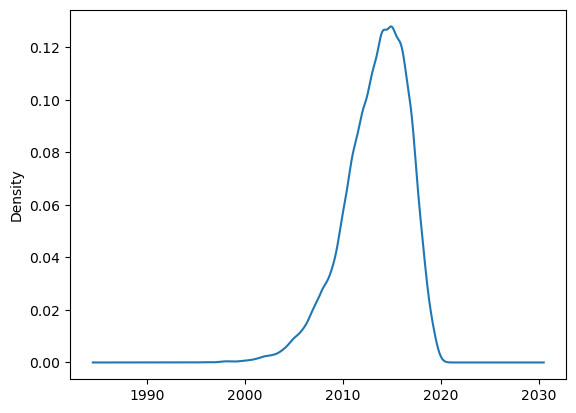

In [28]:
fig = plt.figure()
ax = fig.add_subplot(111)
data['Year'].plot(kind='kde', ax=ax)

<AxesSubplot: ylabel='Density'>

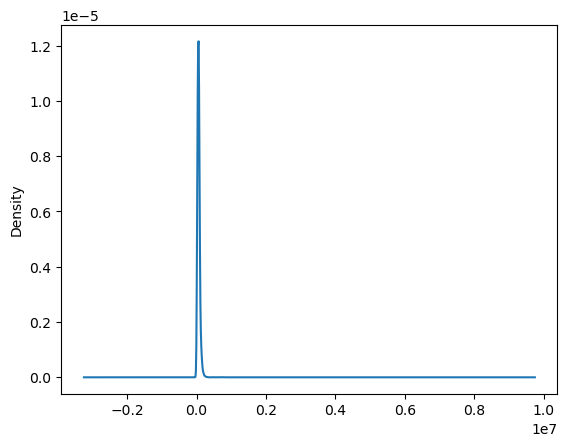

In [29]:
fig = plt.figure()
ax = fig.add_subplot(111)
data['Kilometers_Driven'].plot(kind='kde', ax=ax)

<AxesSubplot: ylabel='Density'>

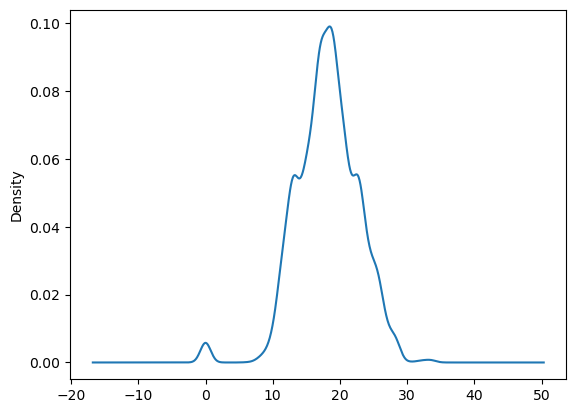

In [30]:
fig = plt.figure()
ax = fig.add_subplot(111)
data['Mileage'].plot(kind='kde', ax=ax)

<AxesSubplot: ylabel='Density'>

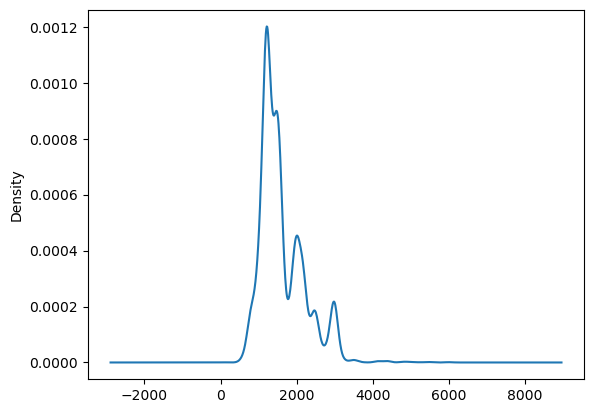

In [31]:
fig = plt.figure()
ax = fig.add_subplot(111)
data['Engine'].plot(kind='kde', ax=ax)

<AxesSubplot: ylabel='Density'>

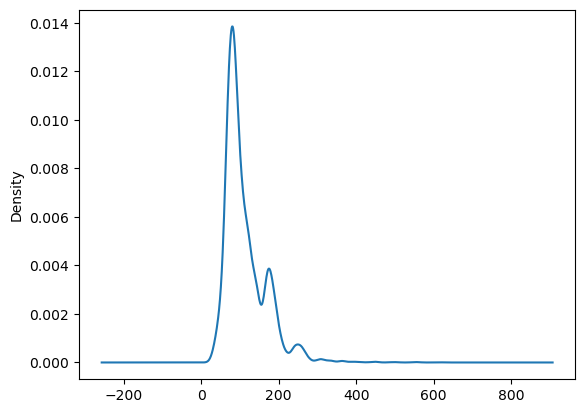

In [32]:
fig = plt.figure()
ax = fig.add_subplot(111)
data['Power'].plot(kind='kde', ax=ax)

<AxesSubplot: ylabel='Density'>

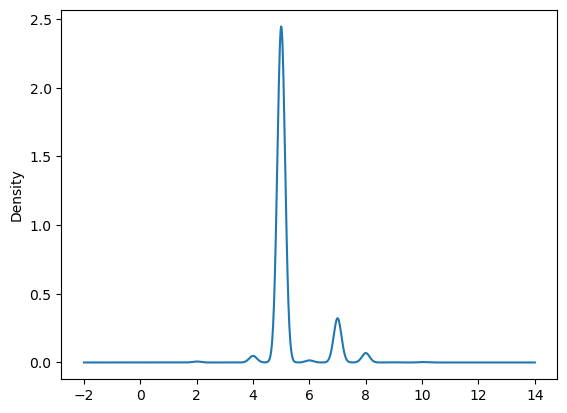

In [33]:
fig = plt.figure()
ax = fig.add_subplot(111)
data['Seats'].plot(kind='kde', ax=ax)

<AxesSubplot: ylabel='Density'>

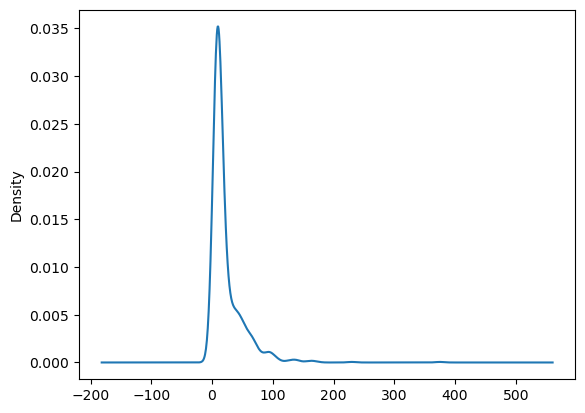

In [34]:
fig = plt.figure()
ax = fig.add_subplot(111)
data['New_price'].plot(kind='kde', ax=ax)

<AxesSubplot: ylabel='Density'>

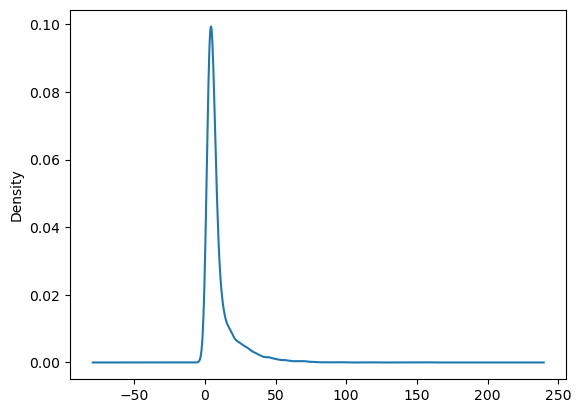

In [35]:
fig = plt.figure()
ax = fig.add_subplot(111)
data['Price'].plot(kind='kde', ax=ax)

In [52]:
# log transforming REVENUE and saving it to the dataset
data['price_log'] = np.log(data['Price'])

<AxesSubplot: ylabel='Density'>

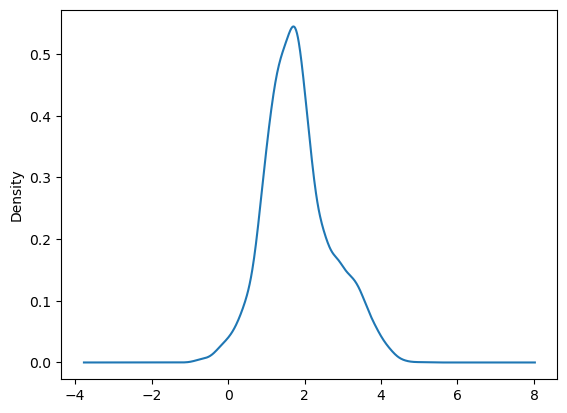

In [53]:
fig = plt.figure()
ax = fig.add_subplot(111)
data['price_log'].plot(kind='kde', ax=ax)

<strong> Categorical variables </strong>
<br>
Name , Location, Fuel_Type, Transmission, Owner_Type

In [46]:
#Fuel_Type
data['Fuel_Type'].value_counts()

Diesel      3852
Petrol      3325
CNG           62
LPG           12
Electric       2
Name: Fuel_Type, dtype: int64

In [47]:
 #Transmission
data['Transmission'].value_counts()

Manual       5204
Automatic    2049
Name: Transmission, dtype: int64

In [48]:
# Owner_Type
data['Owner_Type'].value_counts()

First             5952
Second            1152
Third              137
Fourth & Above      12
Name: Owner_Type, dtype: int64

In [45]:
#location
data['Location'].value_counts()

Mumbai        949
Hyderabad     876
Coimbatore    772
Kochi         772
Pune          765
Delhi         660
Kolkata       654
Chennai       591
Jaipur        499
Bangalore     440
Ahmedabad     275
Name: Location, dtype: int64

## **Bivariate Analysis**

**Questions:**

1. Plot a scatter plot for the log transformed values(if log_transformation done in previous steps)?
2. What can we infer form the correlation heatmap? Is there correlation between the dependent and independent variables?
3. Plot a box plot for target variable and categorical variable 'Location' and write your observations?

In [ ]:
data.plot.scatter(x='length',
                  y='width',
                  c='DarkBlue')

<AxesSubplot: >

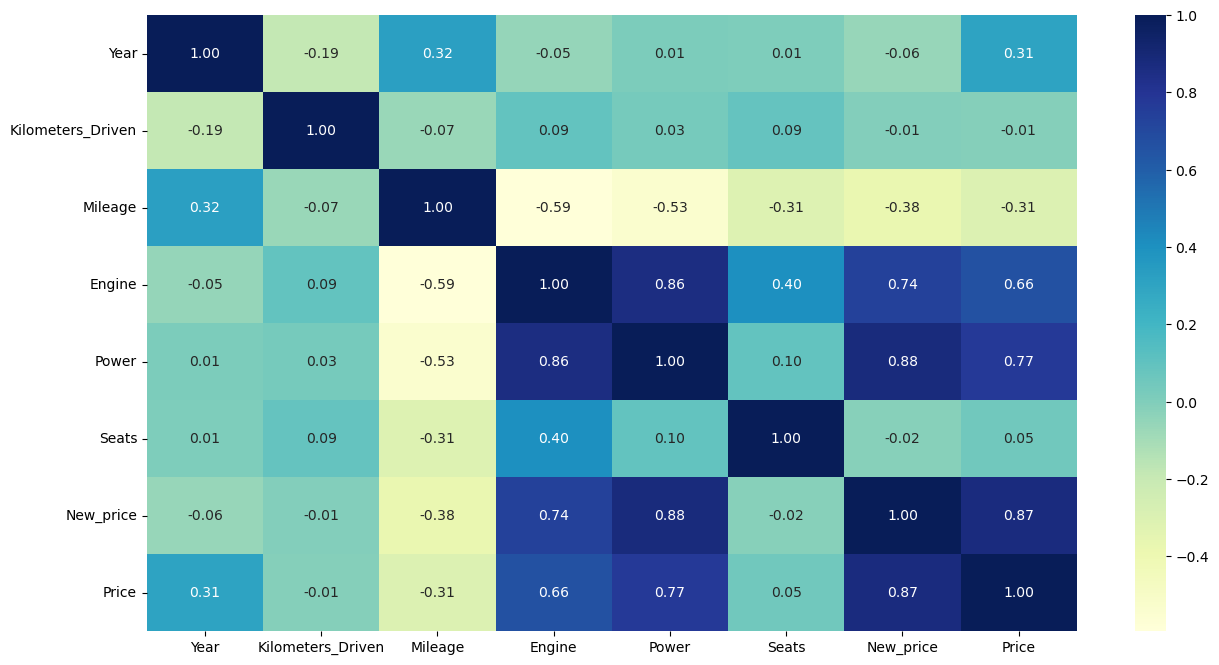

In [51]:
# code here
Col_heat_map = ["Year", "Kilometers_Driven", "Mileage", "Engine", 'Power', 'Seats', 'New_price', 'Price']
# Plotting the correlation between numerical variables
plt.figure(figsize = (15, 8))

sns.heatmap(data[Col_heat_map].corr(), annot = True, fmt = '0.2f', cmap = 'YlGnBu')



### **Feature Engineering**

**Think about it:** The `Name` column in the current format might not be very useful in our analysis.
Since the name contains both the brand name and the model name of the vehicle, the column would have too many unique values to be useful in prediction. Can we extract that information from that column? 

* **Hint:** With 2041 unique names, car names are not going to be great predictors of the price in our current data. But we can process this column to extract important information for example brand name.

In [54]:
data['Name'].value_counts()

Mahindra XUV500 W8 2WD                  55
Maruti Swift VDI                        49
Maruti Swift Dzire VDI                  42
Honda City 1.5 S MT                     39
Maruti Swift VDI BSIV                   37
                                        ..
Chevrolet Beat LT Option                 1
Skoda Rapid 1.6 MPI AT Elegance Plus     1
Ford EcoSport 1.5 TDCi Ambiente          1
Hyundai i10 Magna 1.1 iTech SE           1
Hyundai Elite i20 Magna Plus             1
Name: Name, Length: 2041, dtype: int64

In [73]:
data["Name_Model"] = data['Name'].str.split(' ').str[0]

data["Name_Model"].value_counts()

Maruti           1444
Hyundai          1340
Honda             743
Toyota            507
Mercedes-Benz     380
Volkswagen        374
Ford              351
Mahindra          331
BMW               312
Audi              285
Tata              228
Skoda             202
Renault           170
Chevrolet         151
Nissan            117
Land               67
Jaguar             48
Fiat               38
Mitsubishi         36
Mini               31
Volvo              28
Porsche            19
Jeep               19
Datsun             17
ISUZU               3
Force               3
Isuzu               2
Bentley             2
Smart               1
Ambassador          1
Lamborghini         1
Hindustan           1
OpelCorsa           1
Name: Name_Model, dtype: int64

In [ ]:
# categorical_variables = ['Name', "Location", "Fuel_Type", "Transmission", "Owner_Type"]

In [81]:
DF_Name_Model = pd.get_dummies(data['Name_Model'])
data=data.join([DF_Name_Model])

In [82]:
DF_Location = pd.get_dummies(data['Location'])
data=data.join([DF_Location])

In [83]:
DF_Fuel_Type = pd.get_dummies(data['Fuel_Type'])
data=data.join([DF_Fuel_Type])

In [84]:
DF_Transmission = pd.get_dummies(data['Transmission'])
data=data.join([DF_Transmission])

In [85]:
DF_Owner_Type = pd.get_dummies(data['Owner_Type'])
data=data.join([DF_Owner_Type])

In [86]:
data.head()

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_price,Price,price_log,Name_Model,Ambassador,Audi,BMW,Bentley,Chevrolet,Datsun,Fiat,Force,Ford,Hindustan,Honda,Hyundai,ISUZU,Isuzu,Jaguar,Jeep,Lamborghini,Land,Mahindra,Maruti,Mercedes-Benz,Mini,Mitsubishi,Nissan,OpelCorsa,Porsche,Renault,Skoda,Smart,Tata,Toyota,Volkswagen,Volvo,Ahmedabad,Bangalore,Chennai,Coimbatore,Delhi,Hyderabad,Jaipur,Kochi,Kolkata,Mumbai,Pune,CNG,Diesel,Electric,LPG,Petrol,Automatic,Manual,First,Fourth & Above,Second,Third
0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.60,998.0,58.16,5.0,NaN,1.75,0.559616,Maruti,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,1,0,0,0
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67,1582.0,126.20,5.0,NaN,12.50,2.525729,Hyundai,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,1,0,0,0
2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.20,1199.0,88.70,5.0,8.61,4.50,1.504077,Honda,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0
3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77,1248.0,88.76,7.0,NaN,6.00,1.791759,Maruti,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,1,0,0,0
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.20,1968.0,140.80,5.0,NaN,17.74,2.875822,Audi,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0


In [90]:
# declaring sets of x-variables - already without the variables that will be used as y ('REVENUE' or 'log_REVENUE')

# full_x = ['NAME','EMAIL','FIRST_NAME','FAMILY_NAME','TOTAL_MEALS_ORDERED',
#           'UNIQUE_MEALS_PURCH','CONTACTS_W_CUSTOMER_SERVICE',
#           'PRODUCT_CATEGORIES_VIEWED','AVG_TIME_PER_SITE_VISIT',
#           'CANCELLATIONS_AFTER_NOON','PC_LOGINS','MOBILE_LOGINS',
#           'WEEKLY_PLAN','LATE_DELIVERIES ','AVG_PREP_VID_TIME',
#           'LARGEST_ORDER_SIZE','AVG_MEAN_RATING','TOTAL_PHOTOS_VIEWED','email_domain','domain_group','junk','personal','professional']


# removal of categorical variables such as first name, last name and email from x-variables
reduced_x = ['Year','Kilometers_Driven','Mileage','Engine','Power','Seats','price_log',
             'Ambassador','Audi','BMW','Bentley','Chevrolet','Datsun','Fiat',
             'Force','Ford','Hindustan','Honda','Hyundai','ISUZU','Isuzu',
             'Jaguar','Jeep','Lamborghini','Land','Mahindra','Maruti',
             'Mercedes-Benz','Mini','Mitsubishi','Nissan','OpelCorsa',
             'Porsche','Renault','Skoda','Smart','Tata','Toyota','Volkswagen',
             'Volvo','Ahmedabad','Bangalore','Chennai','Coimbatore','Delhi',
             'Hyderabad','Jaipur','Kochi','Kolkata','Mumbai','Pune','CNG',
             'Diesel','Electric','LPG','Petrol','Automatic','Manual','First',
             'Fourth & Above','Second','Third']


In [104]:
reduced_data = data.drop(['Mumbai','Hyderabad','Coimbatore','Kochi','Pune',
  'Delhi','Kolkata','Chennai','Jaipur','Bangalore',
   'Ahmedabad','First','Second','Third','Fourth & Above','Manual','Automatic',
    'Diesel','Petrol','CNG','LPG','Electric','Maruti','Hyundai','Honda','Toyota','Mercedes-Benz','Volkswagen','Ford',
    'Mahindra','BMW','Audi','Tata','Skoda','Renault','Chevrolet','Nissan',
    'Land','Jaguar','Fiat','Mitsubishi','Mini','Volvo','Porsche','Jeep',
    'Datsun','ISUZU','Force','Isuzu','Bentley','Smart','Ambassador',
    'Lamborghini','Hindustan','OpelCorsa'], axis=1)

df_corr = reduced_data.corr(method = 'pearson').round(decimals=2)

df_corr['Price'].sort_values(ascending = False)

Price                1.00
New_price            0.87
price_log            0.85
Power                0.77
Engine               0.66
Year                 0.31
Seats                0.05
Kilometers_Driven   -0.01
Mileage             -0.31
Name: Price, dtype: float64

In [106]:
# location
location_df = data[['Mumbai','Hyderabad','Coimbatore','Kochi','Pune',
  'Delhi','Kolkata','Chennai','Jaipur','Bangalore',
   'Ahmedabad','Price','New_price','price_log']].copy()
# Owner_Type
Owner_Type_df = data[['First','Second','Third','Fourth & Above',
                      'Price','New_price','price_log']].copy()
# Transmission
Transmission_df = data[['Manual','Automatic',
                        'Price','New_price','price_log']].copy()
# Fuel_Type
Fuel_Type_df = data[['Diesel','Petrol','CNG','LPG',
                     'Electric','Price','New_price','price_log']].copy()
# Name_model
Name_model_df = data[[
'Maruti','Hyundai','Honda','Toyota','Mercedes-Benz','Volkswagen','Ford',
    'Mahindra','BMW','Audi','Tata','Skoda','Renault','Chevrolet','Nissan',
    'Land','Jaguar','Fiat','Mitsubishi','Mini','Volvo','Porsche','Jeep',
    'Datsun','ISUZU','Force','Isuzu','Bentley','Smart','Ambassador',
    'Lamborghini','Hindustan','OpelCorsa',
    'Price','New_price','price_log']].copy()


In [99]:
df_corr = Transmission_df.corr(method = 'pearson').round(decimals=2)

df_corr['Price'].sort_values(ascending = False)

Price        1.00
New_price    0.87
price_log    0.85
Automatic    0.59
Manual      -0.59
Name: Price, dtype: float64

In [107]:
df_corr = location_df.corr(method = 'pearson').round(decimals=2)

df_corr['Price'].sort_values(ascending = False)

Price         1.00
New_price     0.87
price_log     0.85
Coimbatore    0.17
Bangalore     0.09
Kochi         0.05
Hyderabad     0.01
Delhi         0.01
Mumbai       -0.00
Ahmedabad    -0.02
Chennai      -0.05
Pune         -0.08
Jaipur       -0.09
Kolkata      -0.11
Name: Price, dtype: float64

In [98]:
df_corr = Owner_Type_df.corr(method = 'pearson').round(decimals=2)

df_corr['Price'].sort_values(ascending = False)

Price             1.00
New_price         0.87
price_log         0.85
First             0.09
Fourth & Above   -0.02
Third            -0.06
Second           -0.07
Name: Price, dtype: float64

In [100]:
df_corr = Fuel_Type_df.corr(method = 'pearson').round(decimals=2)

df_corr['Price'].sort_values(ascending = False)

Price        1.00
New_price    0.87
price_log    0.85
Diesel       0.32
Electric     0.01
LPG         -0.03
CNG         -0.05
Petrol      -0.31
Name: Price, dtype: float64

In [101]:
df_corr = Name_model_df.corr(method = 'pearson').round(decimals=2)

df_corr['Price'].sort_values(ascending = False)

Price            1.00
New_price        0.87
price_log        0.85
Mercedes-Benz    0.37
BMW              0.30
Audi             0.29
Land             0.27
Jaguar           0.21
Porsche          0.19
Lamborghini      0.13
Mini             0.10
Bentley          0.06
Toyota           0.05
Volvo            0.05
Jeep             0.04
Isuzu            0.01
Mitsubishi       0.01
ISUZU            0.00
Force           -0.00
Smart           -0.01
Ambassador      -0.01
Skoda           -0.03
Mahindra        -0.03
Datsun          -0.03
Fiat            -0.04
Nissan          -0.05
Renault         -0.05
Ford            -0.05
Chevrolet       -0.08
Tata            -0.09
Volkswagen      -0.09
Honda           -0.12
Hyundai         -0.18
Maruti          -0.22
Hindustan         NaN
OpelCorsa         NaN
Name: Price, dtype: float64

Creating the first model, where all categorical variables will have their values ​​changed to 0 and 1 to understand which one has a better correlation with the Price variable, after that I will take for each of these variables which of their categories had a greater correlation and I will create the variables that are in that category and I will group the others as non_category variables.
<br>
Example for the Name_model variable that was just created with the name of the car models, we can have *Nissan* as the variable with the highest correlation with the price variable, so I will create the category *Nissan* and the category *Not_Nissan*, the which will encompass the other variables, as these variables are self-excluding, that is, if a car is *Nissan* there is no way it can be *Ford*, so I will make this division for the continuity of the analyses.

In [109]:
# location_df types
Coimbatore = ['Coimbatore']
Not_Coimbatore =['Bangalore',
'Kochi'    ,
'Hyderabad',
'Delhi'    ,
'Mumbai'   ,
'Ahmedabad',
'Chennai'  ,
'Pune'     ,
'Jaipur'   ,
'Kolkata'  ]

# placeholder list
placeholder_lst = []


# looping to group observations by domain type
for domain in data['Location']:
    
    if domain in Coimbatore:
        placeholder_lst.append('Coimbatore')
    elif domain in Not_Coimbatore:
        placeholder_lst.append('Not_Coimbatore')

    else:
          #  print('Unknown',domain )
             print('Unknown')

# concatenating with original DataFrame
data['Location'] = pd.Series(placeholder_lst)

# checking results
data['Location'].value_counts()

Not_Coimbatore    6481
Coimbatore         772
Name: Location, dtype: int64

In [110]:
# one hot encoding categorical variables
DF_Location = pd.get_dummies(data['Location'])

# dropping categorical variables after they've been encoded


# joining codings together
data = data.join([DF_Location])


data = data.drop('Location', axis = 1)


ValueError: Indexes have overlapping values: Index(['Coimbatore'], dtype='object')

In [111]:
# location_df types
First = ['First']
Not_First =['Fourth & Above',
'Third',
'Second']

# placeholder list
placeholder_lst = []


# looping to group observations by domain type
for domain in data['Owner_Type']:
    
    if domain in First:
        placeholder_lst.append('First')
    elif domain in Not_First:
        placeholder_lst.append('Not_First')

    else:
          #  print('Unknown',domain )
             print('Unknown')

# concatenating with original DataFrame
data['Owner_Type'] = pd.Series(placeholder_lst)

# checking results
data['Owner_Type'].value_counts()

First        5952
Not_First    1301
Name: Owner_Type, dtype: int64

In [112]:
# one hot encoding categorical variables
DF_Owner_Type = pd.get_dummies(data['Owner_Type'])

# dropping categorical variables after they've been encoded


# joining codings together
data = data.join([DF_Owner_Type])


data = data.drop('Owner_Type', axis = 1)


ValueError: Indexes have overlapping values: Index(['First'], dtype='object')

In [116]:
# location_df types
Diesel = ['Diesel']
Not_Diesel =['Electric',
'LPG',    
'CNG',     
'Petrol']

# placeholder list
placeholder_lst = []


# looping to group observations by domain type
for domain in data['Fuel_Type']:
    
    if domain in Diesel:
        placeholder_lst.append('Diesel')
    elif domain in Not_Diesel:
        placeholder_lst.append('Not_Diesel')

    else:
          #  print('Unknown',domain )
             print('Unknown')

# concatenating with original DataFrame
data['Fuel_Type'] = pd.Series(placeholder_lst)

# checking results
data['Fuel_Type'].value_counts()

Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown
Unknown


Series([], Name: Fuel_Type, dtype: int64)

In [ ]:
# one hot encoding categorical variables
DF_Fuel_Type = pd.get_dummies(data['Fuel_Type'])

# dropping categorical variables after they've been encoded


# joining codings together
data = data.join([DF_Fuel_Type])


data = data.drop('Fuel_Type', axis = 1)


In [ ]:
# location_df types
Mercedes = ['Mercedes-Benz ']
Not_Mercedes =['Electric',
'LPG',    
'CNG',     
'Petrol']

# placeholder list
placeholder_lst = []


# looping to group observations by domain type
for domain in data['Name_model']:
    
    if domain in Diesel:
        placeholder_lst.append('Diesel')
    elif domain in Not_Diesel:
        placeholder_lst.append('Not_Diesel')

    else:
          #  print('Unknown',domain )
             print('Unknown')

# concatenating with original DataFrame
data['Name_model'] = pd.Series(placeholder_lst)

# checking results
data['Name_model'].value_counts()

In [ ]:
# one hot encoding categorical variables
DF_Name_model = pd.get_dummies(data['Name_model'])

# dropping categorical variables after they've been encoded


# joining codings together
data = data.join([DF_Name_model])


data = data.drop('Name_model', axis = 1)


### **Missing value treatment**

## **Important Insights from EDA and Data Preprocessing**

What are the the most important observations and insights from the data based on the EDA and Data Preprocessing performed?

## **Building Various Models**


1. What we want to predict is the "Price". We will use the normalized version 'price_log' for modeling.
2. Before we proceed to the model, we'll have to encode categorical features. We will drop categorical features like Name. 
3. We'll split the data into train and test, to be able to evaluate the model that we build on the train data.
4. Build Regression models using train data.
5. Evaluate the model performance.

### **Split the Data**

<li>Step1: Seperating the indepdent variables (X) and the dependent variable (y). 
<li>Step2: Encode the categorical variables in X using pd.dummies.
<li>Step3: Split the data into train and test using train_test_split.

**Question:** 

1. Why we should drop 'Name','Price','price_log','Kilometers_Driven' from X before splitting?

For Regression Problems, some of the algorithms used are :<br>

**1) Linear Regression** <br>
**2) Ridge / Lasso Regression** <br>
**3) Decision Trees** <br>
**4) Random Forest** <br>

### **Hyperparameter Tuning: Decision Tree**

**Feature Importance**

### **Hyperparameter Tuning: Random Forest**

**Feature Importance**

## **Conclusions and Recommendations**

**1. Comparison of various techniques and their relative performance based on chosen Metric (Measure of success):** 
- How do different techniques perform? Which one is performing relatively better? Is there scope to improve the performance further?

**2. Refined insights:** 
- What are the most meaningful insights relevant to the problem?

**3. Proposal for the final solution design:** 
- What model do you propose to be adopted? Why is this the best solution to adopt?